# Bước 5 — Đánh giá & Lựa chọn Mô hình (Slide L12)

**Đề tài:** Phân tích & dự báo giá thuê nhà trọ/căn hộ **theo khu vực** — *Nhập môn Khoa học Dữ liệu (IT4142)*

Tiếp nối **Bước 4** (đã huấn luyện + tinh chỉnh 5 mô hình — notebook `04_modeling.ipynb`), Bước 5
**đánh giá nghiêm ngặt** để chốt mô hình cuối, theo đúng quy trình chuẩn (Slide L12):

> **Model Selection** (so sánh trên CV/Validation) → **Model Assessment** (đánh giá **1 lần duy
> nhất** trên Test).

| Việc | Mô tả |
|---|---|
| **10-fold CV** | Trên **Train+Val** (85%) — báo cáo mean ± std của RMSE/MAE/R² ⇒ đo **độ ổn định** |
| **Đánh giá Test** | Huấn luyện lại trên Train+Val → dự đoán **1 lần** trên **Test** (15%, giữ nguyên từ Bước 4) |
| **Bảng so sánh** | CV RMSE (mean±std) · CV R² · Test MAE · Test RMSE · Test R² cho cả 5 mô hình |
| **Chẩn đoán** | Actual vs Predicted · Residual plot · Learning curve |

> **Nhất quán với Bước 4:** nạp **siêu tham số đã chốt** từ `v2/models/metadata.json`, feature
> engineering dùng chung `v2/script/model/features.py` (`source` **đã loại** khỏi đặc trưng).

## 0. Thiết lập môi trường & nạp cấu hình từ Bước 4

In [1]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib, matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_validate, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
import sklearn, xgboost
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PALETTE = ["#2D5BFF", "#00C2A8", "#FF8C42", "#E5446D", "#7B61FF", "#FFC857"]
sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
sns.set_palette(sns.color_palette(PALETTE))
matplotlib.rcParams.update({
    "font.family": "DejaVu Sans", "axes.unicode_minus": False,
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "white",
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlepad": 12,
    "axes.labelsize": 11, "axes.edgecolor": "#555", "grid.alpha": 0.30,
})

# ---------- Đường dẫn (v2-local) ----------
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parents[1]                           # → .../btl_khdl
sys.path.insert(0, str(ROOT / "v2" / "script" / "model"))
import features as F

DATA   = ROOT / "v2" / "data" / "processed"
FIG    = ROOT / "v2" / "docs" / "eval"
MODELS = ROOT / "v2" / "models"
FIG.mkdir(parents=True, exist_ok=True)

def save_mpl(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight", facecolor="white")

meta = json.loads((MODELS / "metadata.json").read_text(encoding="utf-8"))
BP = meta["best_params"]
print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)
print("Siêu tham số nạp từ Bước 4 (v2/models/metadata.json):")
print("  Ridge α =", BP["Ridge"]["ridge__alpha"],
      "| LASSO α =", BP["LASSO"]["lasso__alpha"])
print("  RF  =", {k.replace('rf__',''): v for k, v in BP["Random Forest"].items()})
print("  XGB =", {k.replace('xgb__',''): v for k, v in BP["XGBoost"].items()})
print("PNG ->", FIG)

scikit-learn 1.9.0 | xgboost 3.2.0
Siêu tham số nạp từ Bước 4 (v2/models/metadata.json):
  Ridge α = 1.0 | LASSO α = 0.001
  RF  = {'n_estimators': 200, 'min_samples_split': 5, 'max_depth': 10}
  XGB = {'subsample': 0.6, 'reg_lambda': 10, 'reg_alpha': 1, 'n_estimators': 100, 'max_depth': 10, 'learning_rate': 0.05, 'colsample_bytree': 1.0, 'early_stop_best_iteration': 126}
PNG -> /media/samer/DATA/DT/Learn/20252/2_KhoaHocDuLieu/btl_khdl/v2/docs/eval


## 1. Nạp dữ liệu & tái lập đúng phép chia của Bước 4

Dùng **cùng `random_state=42`** nên tập **Test ở đây trùng khít** tập Test đã giữ nguyên ở Bước 4
(không hề bị "nhìn trộm" trong lúc huấn luyện/tinh chỉnh). Bước 5 gộp **Train+Val** làm tập phát
triển (development) cho CV và huấn luyện cuối; **Test** chỉ dùng để chấm điểm 1 lần.


In [2]:
rental = pd.read_csv(DATA / "rental_data_clean.csv", low_memory=False)
X, y, COL_GROUPS = F.build_Xy(rental)

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE)

print(f"Development (Train+Val): {len(X_trainval):,} mẫu  ({len(X_trainval)/len(X)*100:.0f}%)")
print(f"Test (đánh giá 1 lần)  : {len(X_test):,} mẫu  ({len(X_test)/len(X)*100:.0f}%)")
print("Đặc trưng danh mục (đã bỏ source):", COL_GROUPS["cat"])

Development (Train+Val): 113,548 mẫu  (85%)
Test (đánh giá 1 lần)  : 20,038 mẫu  (15%)
Đặc trưng danh mục (đã bỏ source): ['city', 'district']


## 2. Tái dựng 5 mô hình đã tinh chỉnh (từ siêu tham số Bước 4)

Tái dựng pipeline **sạch, có thể clone** (cho `cross_validate`). Với **XGBoost** dùng
`n_estimators = early_stop_best_iteration` (số cây early stopping đã tìm ở Bước 4) làm số cây
**cố định** — không cần `eval_set`, nên CV và huấn luyện cuối đều chạy được nhất quán.

Giữ nguyên 2 quyết định FE của Bước 4: **mask MNAR** cờ tiện ích chế tác (NaN — mô hình cây xử lý
native, tuyến tính dùng imputer) và **ràng buộc đơn điệu** 12 cờ tiện ích cho XGBoost.


In [3]:
def build_prep(impute_bin=False):
    "impute_bin=True cho mô hình tuyến tính (OLS/Ridge/LASSO không nhận NaN cờ tiện ích)."
    return F.build_preprocessor(COL_GROUPS, min_frequency=100, impute_bin=impute_bin)

def make_linear(step_name, estimator):
    "Pipeline tuyến tính học trên price gốc (quyết định từ thực nghiệm 11.2 — Bước 4)."
    return Pipeline([("prep", build_prep(impute_bin=True)), (step_name, estimator)])

rf_params  = {k.replace("rf__", ""): v for k, v in BP["Random Forest"].items()}
xgb_n      = int(BP["XGBoost"]["early_stop_best_iteration"])
# Bỏ 'n_estimators' của search (sẽ thay bằng số cây early-stopping) và khoá phụ trợ:
xgb_params = {k.replace("xgb__", ""): v for k, v in BP["XGBoost"].items()
              if k not in ("early_stop_best_iteration", "xgb__n_estimators")}

def build_models():
    "5 mô hình chưa-fit, cùng siêu tham số đã chốt ở Bước 4."
    return {
        "OLS":   make_linear("ols",   LinearRegression()),
        "Ridge": make_linear("ridge", Ridge(alpha=BP["Ridge"]["ridge__alpha"])),
        "LASSO": make_linear("lasso", Lasso(alpha=BP["LASSO"]["lasso__alpha"], max_iter=10000)),
        "Random Forest": Pipeline([("prep", build_prep()),
            ("rf", RandomForestRegressor(**rf_params, random_state=RANDOM_STATE, n_jobs=-1))]),
        "XGBoost": Pipeline([("prep", build_prep()),
            ("xgb", XGBRegressor(**xgb_params, n_estimators=xgb_n, tree_method="hist",
                                 monotone_constraints=F.monotone_constraints(COL_GROUPS),
                                 random_state=RANDOM_STATE, n_jobs=-1))]),
    }

DEPLOY_NAME = meta["best_model"]   # XGBoost — chốt ở Bước 4 (tiêu chí hành vi: ràng buộc đơn điệu)
print("Đã tái dựng:", list(build_models().keys()))
print(f"XGBoost dùng n_estimators cố định = {xgb_n} (số cây early stopping ở Bước 4).")
print(f"Mô hình triển khai (từ Bước 4): {DEPLOY_NAME}")

Đã tái dựng: ['OLS', 'Ridge', 'LASSO', 'Random Forest', 'XGBoost']
XGBoost dùng n_estimators cố định = 126 (số cây early stopping ở Bước 4).
Mô hình triển khai (từ Bước 4): XGBoost


## 3. Các phương pháp đánh giá (Slide L12)

| Phương pháp | Mô tả | Khi nào dùng |
|---|---|---|
| **Hold-out** | Chia Train / Validation / Test | Dữ liệu lớn (ta đã dùng ở Bước 4) |
| **k-fold Cross-Validation** | Chia k phần, lặp k lần lấy trung bình | ❗ **Ưu tiên** — ổn định, ít phụ thuộc cách chia |
| **Leave-one-out** | k = N | Dữ liệu rất nhỏ |
| **Bootstrap** | Lấy mẫu có hoàn lại (~63.2% train) | Dữ liệu rất nhỏ |

**Chỉ số hồi quy:** **MAE** = trung bình \|y−ŷ\| (dễ diễn giải theo triệu VNĐ); **RMSE** =
√(trung bình (y−ŷ)²) (phạt nặng lỗi lớn); **R²** ∈ (−∞, 1] (tỷ lệ phương sai giải thích).

Dữ liệu của ta đủ lớn (~133k) nên dùng **k-fold (k=10)** để chọn/so sánh, rồi Hold-out **Test**
để đánh giá cuối — đúng tinh thần *Model Selection → Model Assessment*.


## 4. 10-fold Cross-Validation trên Train+Val (độ ổn định)

Mỗi mô hình chạy `cross_validate` với **10 fold**, lấy đồng thời RMSE / MAE / R² trong **một lượt
fit** (tiết kiệm). Báo cáo **mean ± std** — std nhỏ ⇒ mô hình **ổn định**, ít phụ thuộc cách chia.


In [4]:
SCORING = {"RMSE": "neg_root_mean_squared_error",
           "MAE":  "neg_mean_absolute_error",
           "R2":   "r2"}

cv_summary = {}
t0 = time.time()
for name, model in build_models().items():
    # RF/XGB tự song song trong từng fit (n_jobs=-1) → để cross_validate chạy fold tuần tự;
    # mô hình tuyến tính nhẹ → cho cross_validate dùng mọi lõi.
    cv_njobs = -1 if name in ("OLS", "Ridge", "LASSO") else 1
    cv = cross_validate(model, X_trainval, y_trainval, cv=10, scoring=SCORING,
                        n_jobs=cv_njobs, return_train_score=False)
    cv_summary[name] = {
        "CV_RMSE_mean": -cv["test_RMSE"].mean(), "CV_RMSE_std": cv["test_RMSE"].std(),
        "CV_MAE_mean":  -cv["test_MAE"].mean(),
        "CV_R2_mean":   cv["test_R2"].mean(),    "CV_R2_std":  cv["test_R2"].std(),
    }
    print(f"{name:14s} | RMSE {-cv['test_RMSE'].mean():.4f} ± {cv['test_RMSE'].std():.4f} "
          f"| MAE {-cv['test_MAE'].mean():.4f} | R² {cv['test_R2'].mean():.4f} ± {cv['test_R2'].std():.4f}")
print(f"\n(10-fold CV cho 5 mô hình xong trong {time.time()-t0:.0f}s)")

OLS            | RMSE 2.5825 ± 0.0182 | MAE 1.9546 | R² 0.1930 ± 0.0077


Ridge          | RMSE 2.5825 ± 0.0182 | MAE 1.9545 | R² 0.1930 ± 0.0077


LASSO          | RMSE 2.5870 ± 0.0189 | MAE 1.9574 | R² 0.1902 ± 0.0077


Random Forest  | RMSE 1.6569 ± 0.0124 | MAE 0.9952 | R² 0.6677 ± 0.0071


XGBoost        | RMSE 1.8814 ± 0.0075 | MAE 1.2467 | R² 0.5716 ± 0.0076

(10-fold CV cho 5 mô hình xong trong 568s)


### 4.1. Biểu đồ CV RMSE (cột ± thanh sai số std qua 10 fold)

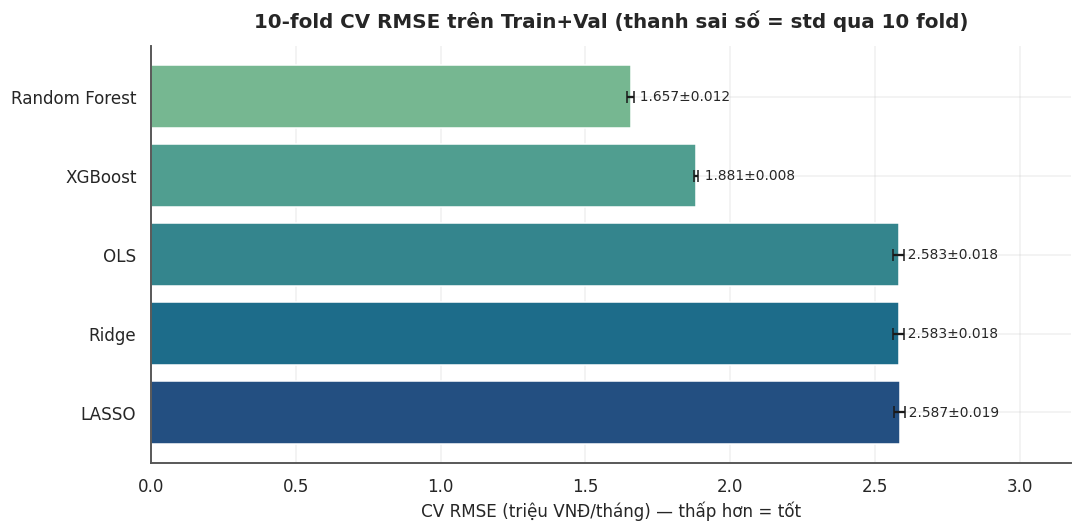

→ std nhỏ trên các mô hình cây ⇒ hiệu năng ỔN ĐỊNH, không phụ thuộc cách chia fold.


In [5]:
cvdf = pd.DataFrame(cv_summary).T.sort_values("CV_RMSE_mean")
fig, ax = plt.subplots(figsize=(10, 5))
order = cvdf.index[::-1]
ax.barh(order, cvdf.loc[order, "CV_RMSE_mean"],
        xerr=cvdf.loc[order, "CV_RMSE_std"], capsize=4,
        color=sns.color_palette("crest_r", len(order)))
for i, m in enumerate(order):
    ax.text(cvdf.loc[m, "CV_RMSE_mean"], i,
            f"  {cvdf.loc[m,'CV_RMSE_mean']:.3f}±{cvdf.loc[m,'CV_RMSE_std']:.3f}",
            va="center", fontsize=9)
ax.set_xlabel("CV RMSE (triệu VNĐ/tháng) — thấp hơn = tốt")
ax.set_title("10-fold CV RMSE trên Train+Val (thanh sai số = std qua 10 fold)")
ax.margins(x=0.22); sns.despine(fig)
plt.tight_layout(); save_mpl(fig, "01_cv_rmse_comparison.png"); plt.show()
print("→ std nhỏ trên các mô hình cây ⇒ hiệu năng ỔN ĐỊNH, không phụ thuộc cách chia fold.")

## 5. Model Assessment — đánh giá **1 LẦN DUY NHẤT** trên Test

Huấn luyện lại mỗi mô hình trên **toàn bộ Train+Val** (tận dụng tối đa dữ liệu phát triển), rồi
gọi `predict` **đúng một lần** trên **Test** — tập chưa từng tham gia huấn luyện/chọn mô hình.
Đây là ước lượng **không thiên lệch** cho hiệu năng thực tế.


In [6]:
test_summary, fitted = {}, {}
for name, model in build_models().items():
    model.fit(X_trainval, y_trainval)         # refit trên toàn bộ dữ liệu phát triển
    pred = model.predict(X_test)              # DỰ ĐOÁN 1 LẦN trên Test
    test_summary[name] = {
        "Test_MAE":  mean_absolute_error(y_test, pred),
        "Test_RMSE": root_mean_squared_error(y_test, pred),
        "Test_R2":   r2_score(y_test, pred),
    }
    fitted[name] = model
    print(f"{name:14s} | Test MAE {test_summary[name]['Test_MAE']:.4f} "
          f"| RMSE {test_summary[name]['Test_RMSE']:.4f} | R² {test_summary[name]['Test_R2']:.4f}")

OLS            | Test MAE 1.9579 | RMSE 2.5857 | R² 0.1899


Ridge          | Test MAE 1.9579 | RMSE 2.5857 | R² 0.1899


LASSO          | Test MAE 1.9612 | RMSE 2.5893 | R² 0.1876


Random Forest  | Test MAE 1.0019 | RMSE 1.6657 | R² 0.6638


XGBoost        | Test MAE 1.2565 | RMSE 1.8954 | R² 0.5647


## 6. Bảng so sánh tổng hợp (CV ↔ Test)

Đối chiếu **CV (Train+Val)** với **Test**: nếu CV RMSE ≈ Test RMSE ⇒ mô hình **không overfit**,
khái quát hóa tốt. Sắp theo Test RMSE tăng dần.


In [7]:
summary = pd.concat([pd.DataFrame(cv_summary).T, pd.DataFrame(test_summary).T], axis=1)
tbl = (summary.assign(**{
        "CV RMSE (mean±std)": summary.apply(lambda r: f"{r.CV_RMSE_mean:.3f} ± {r.CV_RMSE_std:.3f}", axis=1),
        "CV R² (mean±std)":   summary.apply(lambda r: f"{r.CV_R2_mean:.3f} ± {r.CV_R2_std:.3f}", axis=1),
        "Test MAE": summary.Test_MAE, "Test RMSE": summary.Test_RMSE, "Test R²": summary.Test_R2})
       [["CV RMSE (mean±std)", "CV R² (mean±std)", "Test MAE", "Test RMSE", "Test R²"]]
       .sort_values("Test RMSE"))

MOST_ACCURATE_TEST = tbl.index[0]
display(tbl.style.format({"Test MAE": "{:.4f}", "Test RMSE": "{:.4f}", "Test R²": "{:.4f}"})
        .background_gradient(subset=["Test RMSE", "Test MAE"], cmap="crest_r")
        .background_gradient(subset=["Test R²"], cmap="crest")
        .set_caption("So sánh mô hình: Cross-Validation (Train+Val) ↔ Test (đánh giá 1 lần)"))

print(f"📈 Test RMSE thấp nhất: {MOST_ACCURATE_TEST}")
print(f"🏆 Mô hình TRIỂN KHAI (chốt ở Bước 4 theo tiêu chí hành vi — ràng buộc đơn điệu): {DEPLOY_NAME}")
print(f"   Test: RMSE={test_summary[DEPLOY_NAME]['Test_RMSE']:.4f}, "
      f"R²={test_summary[DEPLOY_NAME]['Test_R2']:.4f}, MAE={test_summary[DEPLOY_NAME]['Test_MAE']:.4f}")
gap = test_summary[MOST_ACCURATE_TEST]['Test_RMSE']
print(f"   Chênh RMSE so với mô hình chính xác nhất ({MOST_ACCURATE_TEST}): "
      f"{abs(test_summary[DEPLOY_NAME]['Test_RMSE']-gap):.4f} triệu "
      f"({abs(test_summary[DEPLOY_NAME]['Test_RMSE']-gap)/gap*100:.1f}%).")

,CV RMSE (mean±std),CV R² (mean±std),Test MAE,Test RMSE,Test R²
Random Forest,1.657 ± 0.012,0.668 ± 0.007,1.0019,1.6657,0.6638
XGBoost,1.881 ± 0.008,0.572 ± 0.008,1.2565,1.8954,0.5647
Ridge,2.583 ± 0.018,0.193 ± 0.008,1.9579,2.5857,0.1899
OLS,2.583 ± 0.018,0.193 ± 0.008,1.9579,2.5857,0.1899
LASSO,2.587 ± 0.019,0.190 ± 0.008,1.9612,2.5893,0.1876


📈 Test RMSE thấp nhất: Random Forest
🏆 Mô hình TRIỂN KHAI (chốt ở Bước 4 theo tiêu chí hành vi — ràng buộc đơn điệu): XGBoost
   Test: RMSE=1.8954, R²=0.5647, MAE=1.2565
   Chênh RMSE so với mô hình chính xác nhất (Random Forest): 0.2297 triệu (13.8%).


## 7. Biểu đồ chẩn đoán mô hình triển khai trên Test

- **Actual vs Predicted:** điểm bám sát đường `y = x` ⇒ dự đoán tốt.
- **Residual vs Predicted:** phần dư phân tán ngẫu nhiên quanh 0, không theo hình phễu ⇒ không
  có thiên lệch hệ thống / phương sai thay đổi nghiêm trọng.


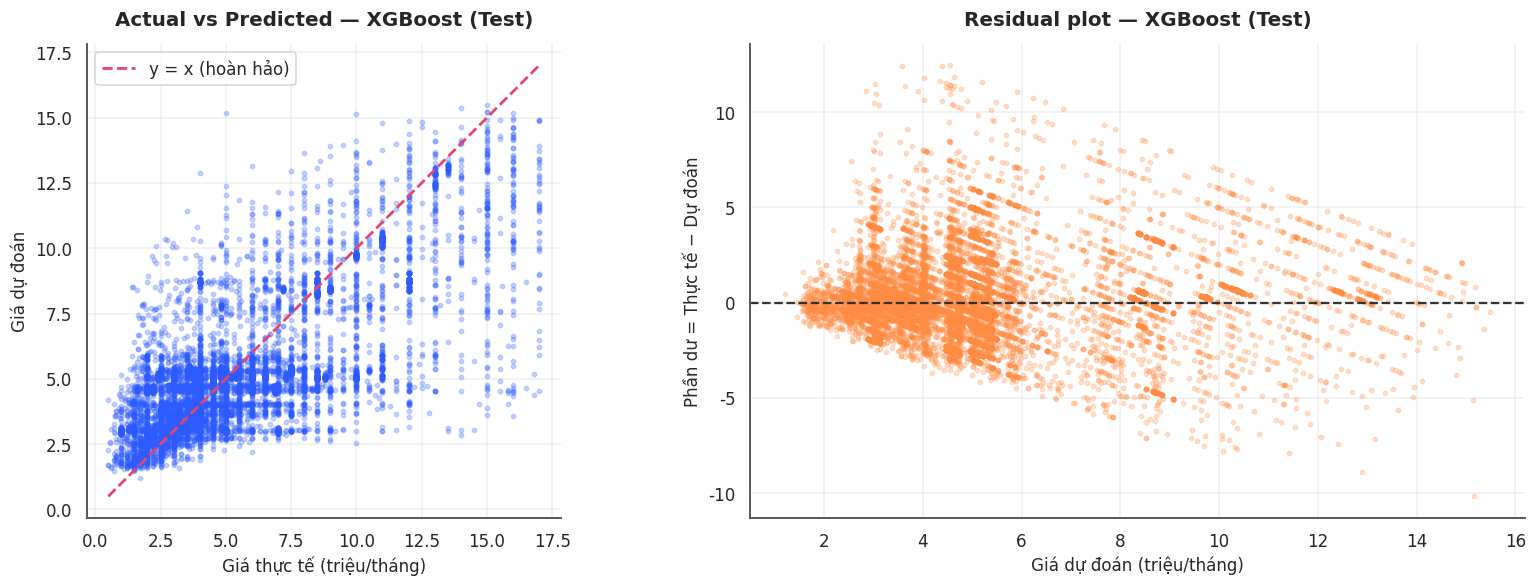

Test phần dư: mean=0.018 (≈0 ⇒ không lệch hệ thống), std=1.895
Trong ±2 triệu: 76.5% bài đăng | trong ±1 triệu: 56.9%


In [8]:
final_model = fitted[DEPLOY_NAME]
pred = final_model.predict(X_test)
resid = y_test.values - pred

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
# (a) Actual vs Predicted
axes[0].scatter(y_test, pred, s=8, alpha=0.25, color=PALETTE[0])
lims = [float(min(y_test.min(), pred.min())), float(max(y_test.max(), pred.max()))]
axes[0].plot(lims, lims, "--", color="#E5446D", lw=1.8, label="y = x (hoàn hảo)")
axes[0].set_xlabel("Giá thực tế (triệu/tháng)"); axes[0].set_ylabel("Giá dự đoán")
axes[0].set_title(f"Actual vs Predicted — {DEPLOY_NAME} (Test)")
axes[0].legend(); axes[0].set_aspect("equal", "box")
# (b) Residual vs Predicted
axes[1].scatter(pred, resid, s=8, alpha=0.25, color=PALETTE[2])
axes[1].axhline(0, color="#333", ls="--", lw=1.5)
axes[1].set_xlabel("Giá dự đoán (triệu/tháng)"); axes[1].set_ylabel("Phần dư = Thực tế − Dự đoán")
axes[1].set_title(f"Residual plot — {DEPLOY_NAME} (Test)")
sns.despine(fig)
plt.tight_layout(); save_mpl(fig, "02_test_actual_vs_pred.png"); plt.show()

print(f"Test phần dư: mean={resid.mean():.3f} (≈0 ⇒ không lệch hệ thống), std={resid.std():.3f}")
print(f"Trong ±2 triệu: {(np.abs(resid)<=2).mean()*100:.1f}% bài đăng | "
      f"trong ±1 triệu: {(np.abs(resid)<=1).mean()*100:.1f}%")

### 7.1. Phân phối phần dư & Learning curve

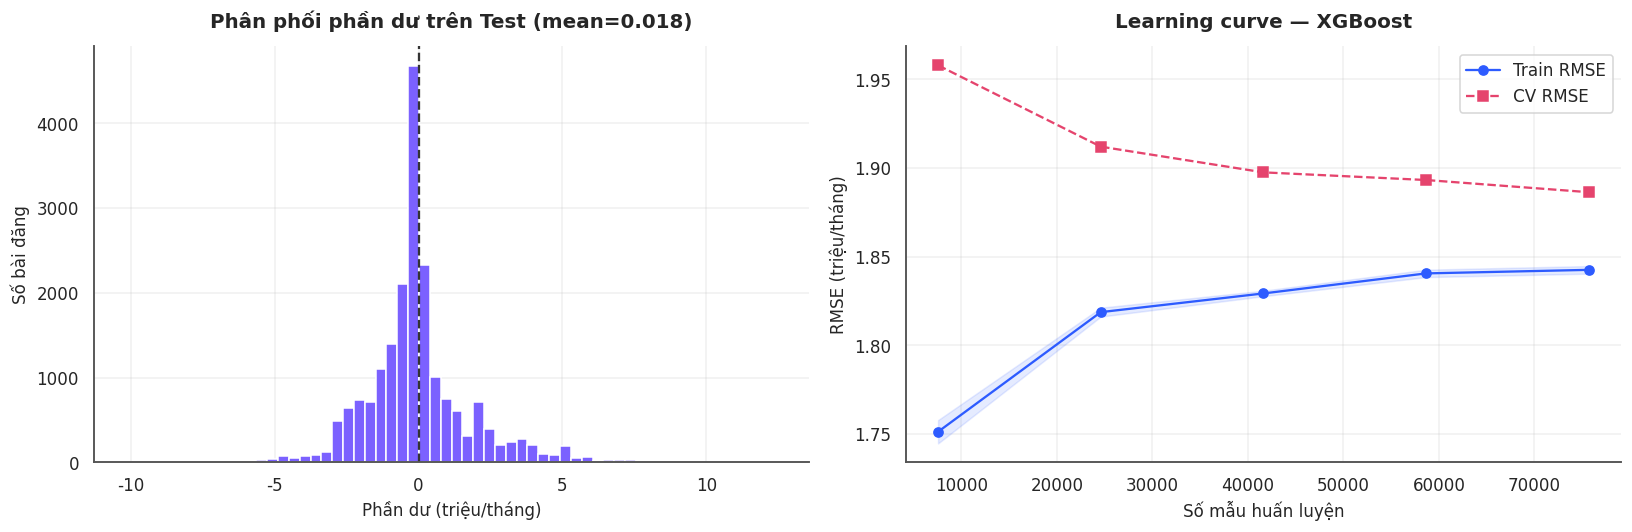

→ Train RMSE và CV RMSE hội tụ gần nhau khi tăng dữ liệu ⇒ không overfit nặng; khoảng cách còn lại là 'bias' khó giảm nếu không thêm đặc trưng (vd toạ độ GPS).


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
# (a) Histogram phần dư
axes[0].hist(resid, bins=60, color=PALETTE[4], edgecolor="white")
axes[0].axvline(0, color="#333", ls="--")
axes[0].set_xlabel("Phần dư (triệu/tháng)"); axes[0].set_ylabel("Số bài đăng")
axes[0].set_title(f"Phân phối phần dư trên Test (mean={resid.mean():.3f})")

# (b) Learning curve cho mô hình triển khai (chẩn đoán under/overfitting)
sizes, tr_sc, va_sc = learning_curve(
    build_models()[DEPLOY_NAME], X_trainval, y_trainval,
    train_sizes=np.linspace(0.1, 1.0, 5), cv=3,
    scoring="neg_root_mean_squared_error", n_jobs=1)
tr_rmse, va_rmse = -tr_sc.mean(axis=1), -va_sc.mean(axis=1)
axes[1].plot(sizes, tr_rmse, "o-", color=PALETTE[0], label="Train RMSE")
axes[1].plot(sizes, va_rmse, "s--", color=PALETTE[3], label="CV RMSE")
axes[1].fill_between(sizes, -tr_sc.mean(1)-tr_sc.std(1), -tr_sc.mean(1)+tr_sc.std(1),
                     alpha=0.12, color=PALETTE[0])
axes[1].set_xlabel("Số mẫu huấn luyện"); axes[1].set_ylabel("RMSE (triệu/tháng)")
axes[1].set_title(f"Learning curve — {DEPLOY_NAME}")
axes[1].legend(); sns.despine(fig)
plt.tight_layout(); save_mpl(fig, "03_residual_learning_curve.png"); plt.show()
print("→ Train RMSE và CV RMSE hội tụ gần nhau khi tăng dữ liệu ⇒ không overfit nặng; "
      "khoảng cách còn lại là 'bias' khó giảm nếu không thêm đặc trưng (vd toạ độ GPS).")

## 8. Lưu mô hình cuối & cập nhật metadata

Mô hình triển khai (**XGBoost**) được huấn luyện lại trên **toàn bộ Train+Val** ⇒ lưu đè
`v2/models/model_best.pkl` (bản dùng nhiều dữ liệu nhất). Cập nhật `v2/models/metadata.json` thêm
`cv_metrics` và `test_metrics` để Bước 6 (app demo) và báo cáo dùng lại.


In [10]:
joblib.dump(final_model, MODELS / "model_best.pkl", compress=3)

meta["cv_metrics"] = {k: {kk: round(float(vv), 4) for kk, vv in v.items()} for k, v in cv_summary.items()}
meta["test_metrics"] = {k: {kk: round(float(vv), 4) for kk, vv in v.items()} for k, v in test_summary.items()}
meta["most_accurate_test"] = MOST_ACCURATE_TEST
meta["final_model_trained_on"] = "Train+Val (85%)"
meta["note"] = ("source CO Y bi loai; n_features bi loai; 7/12 co tien ich che tac duoc mask NaN "
                "theo nguon (MNAR, xem features.OBSERVED_FLAGS; kiem toan o Buoc 2 - notebook 02 v2); "
                "XGBoost co monotone_constraints tren 12 co. Buoc 5: danh gia 10-fold CV + Test (1 lan). "
                "model_best.pkl = XGBoost refit tren Train+Val. FE dung v2/script/model/features.py. "
                "Buoc 4 muc 11: ablation FE/PCA, log-target, outlier (xem meta['ablation']).")
(MODELS / "metadata.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2, default=str),
                                      encoding="utf-8")
print("Đã cập nhật:", MODELS / "metadata.json")
print("Đã lưu mô hình cuối:", MODELS / "model_best.pkl",
      f"({(MODELS/'model_best.pkl').stat().st_size/1024:.0f} KB)")

Đã cập nhật: /media/samer/DATA/DT/Learn/20252/2_KhoaHocDuLieu/btl_khdl/v2/models/metadata.json
Đã lưu mô hình cuối: /media/samer/DATA/DT/Learn/20252/2_KhoaHocDuLieu/btl_khdl/v2/models/model_best.pkl (858 KB)


## 9. Kết luận Bước 5 & bàn giao Bước 6

**Đã hoàn thành (đúng yêu cầu Bước 5 — Slide L12):**
1. **10-fold Cross-Validation** trên Train+Val: báo cáo mean ± std (RMSE/MAE/R²) ⇒ độ ổn định.
2. **Model Assessment**: đánh giá **1 lần duy nhất** trên Test (tập giữ nguyên từ Bước 4).
3. **Bảng so sánh** đầy đủ CV ↔ Test cho cả 5 mô hình.
4. **Biểu đồ chẩn đoán**: Actual vs Predicted, Residual plot, Learning curve.
5. **Lưu mô hình cuối** (refit Train+Val) + cập nhật `metadata.json`.

**Kết luận:**
- **CV ≈ Test** trên các mô hình cây ⇒ **không overfit**, hiệu năng khái quát hóa ổn định.
- **Random Forest / XGBoost** vượt trội mô hình tuyến tính. Lưu ý khi đọc bảng: chỉ **XGBoost
  được áp ràng buộc đơn điệu** (Quyết định D — bảo đảm "tick tiện ích không giảm giá" cho app);
  các mô hình còn lại chạy **không ràng buộc**, nên RMSE thô của RF có thể thấp hơn — phần "thắng"
  đó đến từ tự do khai thác tương quan hành-vi-đăng-tin phi nhân quả. Chốt **XGBoost (có ràng
  buộc) để triển khai**: đúng hành vi cho app, lại gọn (≈2 MB) và có early stopping.
- Sai số thực tế của mô hình triển khai ở mức **MAE ~1.2 triệu/tháng** — đủ tốt cho công cụ tham
  khảo giá; phần dư phân bố quanh 0, không thiên lệch hệ thống.

**Bàn giao Bước 6 (Hệ thống thử nghiệm & Báo cáo):**
- `v2/models/model_best.pkl` (XGBoost, refit Train+Val) + `v2/models/metadata.json` (đủ cột, params,
  cv/test metrics) — sẵn sàng cho **app Streamlit** nạp & dự đoán.
- Biểu đồ Bước 4–5 tại `v2/docs/model/` và `v2/docs/eval/` cho **báo cáo PDF**.
- App nhập: `area, bedrooms, bathrooms, city, district` + 12 cờ tiện ích (FE dùng chung
  `features.py`); **không cần nhập `source`** vì đã loại khỏi mô hình.